# Purchase Intention on UCI Online Shoppers Dataset (reproducing Thanh_Paper2's modeling pipeline)

Paper gốc (`Thanh_Paper2.pdf`) dự đoán **purchase vs. abandonment** dựa trên feature cấp session, dùng RQ1 (category transitions) và RQ2 (price dynamics). Notebook `Cart_Abandonment_REES46.ipynb` tái hiện điều đó trên REES46, nhưng REES46 thiếu geo/device (bỏ RQ3) và F1 thấp hơn paper khá nhiều.

Notebook này dùng **UCI Online Shoppers Purchasing Intention Dataset** (`data_ecommerce/online_shoppers_intention.csv`, 12,330 session, đã được tác giả gốc tính sẵn feature cấp session, không cần tự build từ raw event log). Đổi lại: dataset này **không có thông tin giá sản phẩm hay danh mục**, nên **không trả lời được RQ1 (category) và RQ2 (price)** như paper — notebook này dùng cùng pipeline mô hình (8 model + CNN_LSTM_Maxout) nhưng trả lời câu hỏi khác: **những tín hiệu hành vi/kỹ thuật nào (độ sâu duyệt web, PageValues, loại visitor, tháng, vùng, thiết bị) dự đoán tốt nhất khả năng mua hàng?**

In [1]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score, roc_auc_score, precision_score, recall_score, f1_score, confusion_matrix, roc_curve
from imblearn.over_sampling import SMOTE
import shap

In [2]:
#Fix the random seed
seed = 42
np.random.seed(seed)
torch.manual_seed(seed)
devices = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(devices)

cuda


In [3]:
#Directory to store trained model checkpoints (sklearn: .joblib, PyTorch: .pt state_dict)
#Separate subfolder from the REES46 notebook's checkpoints so filenames (LR.joblib, CNN.pt, ...) don't collide
checkpoint_dir = 'checkpoints/uci'
os.makedirs(checkpoint_dir, exist_ok=True)
os.makedirs('outputs', exist_ok=True)

Load UCI Online Shoppers Purchasing Intention Dataset

Mỗi dòng là 1 session đã được tổng hợp sẵn: số trang xem theo loại (Administrative/Informational/ProductRelated) và thời gian trên trang, BounceRates/ExitRates, PageValues (giá trị trang trước khi mua), SpecialDay, Month, OperatingSystems, Browser, Region, TrafficType, VisitorType, Weekend. Nhãn `Revenue` = có mua hàng hay không.

In [4]:
df = pd.read_csv('data_ecommerce/online_shoppers_intention.csv')
print(df.shape)
print(df.isna().sum().sum(), 'missing values')
df.head()

(12330, 18)
0 missing values


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


Preprocessing: Encode Categorical Columns

Không cần feature engineering từ raw log như REES46 vì dataset đã ở cấp session. Chỉ encode 2 cột dạng chữ (`Month`, `VisitorType`) và 2 cột boolean (`Weekend`, `Revenue`) thành số.

In [5]:
#Month kept in calendar order (ordinal), VisitorType label-encoded; Weekend/Revenue cast to int
month_map = {'Feb': 2, 'Mar': 3, 'Apr': 4, 'May': 5, 'June': 6, 'Jul': 7, 'Aug': 8, 'Sep': 9, 'Oct': 10, 'Nov': 11, 'Dec': 12}
visitor_map = {'Returning_Visitor': 0, 'New_Visitor': 1, 'Other': 2}
df['Month_enc'] = df['Month'].map(month_map)
df['VisitorType_enc'] = df['VisitorType'].map(visitor_map)
df['Weekend_int'] = df['Weekend'].astype(int)
df['purchase'] = df['Revenue'].astype(int)
print(df['purchase'].value_counts(normalize=True))

purchase
0    0.845255
1    0.154745
Name: proportion, dtype: float64


Dataset Analysis

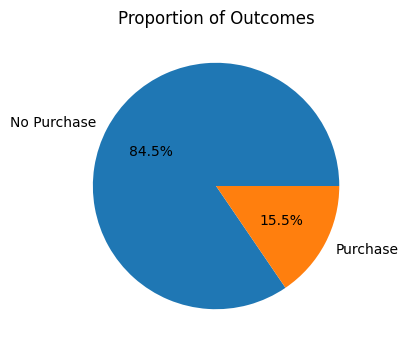

In [6]:
#Plot the outcome balance
fig, ax = plt.subplots(figsize=(4, 4))
df['purchase'].value_counts().plot.pie(
    labels=['No Purchase', 'Purchase'], autopct='%1.1f%%', ax=ax, colors=['#1f77b4', '#ff7f0e'])
ax.set_ylabel('')
ax.set_title('Proportion of Outcomes')
plt.show()

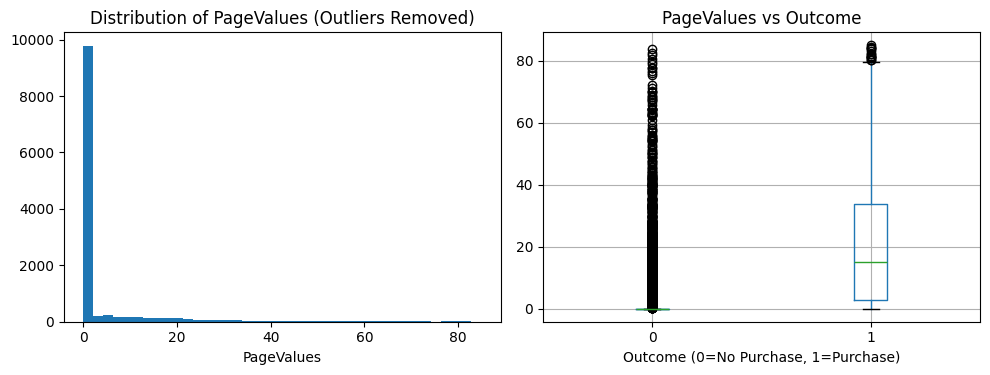

In [7]:
#Plot PageValues distribution vs outcome (this dataset has no product price, PageValues is the closest "value" signal)
pv_clip = df[df['PageValues'] < df['PageValues'].quantile(0.99)]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].hist(pv_clip['PageValues'], bins=40)
axes[0].set_title('Distribution of PageValues (Outliers Removed)')
axes[0].set_xlabel('PageValues')
pv_clip.boxplot(column='PageValues', by='purchase', ax=axes[1])
axes[1].set_title('PageValues vs Outcome')
axes[1].set_xlabel('Outcome (0=No Purchase, 1=Purchase)')
plt.suptitle('')
plt.tight_layout()
plt.show()

Train/Test Split + SMOTE (SMOTE fitted on the training split only, to avoid leakage)

In [8]:
feature_cols = ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration',
                'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues',
                'SpecialDay', 'Month_enc', 'OperatingSystems', 'Browser', 'Region', 'TrafficType',
                'VisitorType_enc', 'Weekend_int']

X = df[feature_cols].values.astype(np.float32)
y = df['purchase'].values.astype(np.int64)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=seed)

smote = SMOTE(random_state=seed)
X_train_bal, y_train_bal = smote.fit_resample(X_train, y_train)
print('Before SMOTE:', np.bincount(y_train))
print('After SMOTE:', np.bincount(y_train_bal))

#Carve a validation split out of the balanced training set, used only to track learning curves (test set stays fully held out)
X_tr, X_val, y_tr, y_val = train_test_split(X_train_bal, y_train_bal, test_size=0.15, stratify=y_train_bal, random_state=seed)

Before SMOTE: [8338 1526]
After SMOTE: [8338 8338]


Dataset/DataLoader for the Deep Learning Models

In [9]:
class SessionDataset(Dataset):
    def __init__(self, X, y):
        self.X = X
        self.y = y

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return torch.tensor(self.X[idx], dtype=torch.float32), torch.tensor(self.y[idx], dtype=torch.float32)

In [10]:
batch_size = 64
train_dataset = SessionDataset(X_tr, y_tr)
val_dataset = SessionDataset(X_val, y_val)
test_dataset = SessionDataset(X_test, y_test)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

#Show the data
batch = next(iter(train_loader))
print(batch[0].shape)  # (batch_size, num_features)
print(batch[1].shape)  # (batch_size,)

torch.Size([64, 17])
torch.Size([64])


Build The Models

In [11]:
#MLP: Dense(128, ReLU) -> Dropout(0.3) -> Dense(64, ReLU) -> Dropout(0.3) -> Dense(1, Sigmoid)
class MLP(nn.Module):
    def __init__(self, in_features, drop=0.3):
        super(MLP, self).__init__()
        self.fc1 = nn.Linear(in_features, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, 1)
        self.relu = nn.ReLU()
        self.drop = nn.Dropout(drop)

    def forward(self, x):
        x = self.drop(self.relu(self.fc1(x)))
        x = self.drop(self.relu(self.fc2(x)))
        x = torch.sigmoid(self.fc3(x))
        return x.squeeze(-1)

In [12]:
#CNN1D: Conv1D(64) -> MaxPooling -> Conv1D(32) -> Flatten -> Dense(64, ReLU) -> Dropout(0.3) -> Dense(1, Sigmoid)
#Each input feature is treated as one time step with 1 channel
class CNN1D(nn.Module):
    def __init__(self, num_features, drop=0.3):
        super(CNN1D, self).__init__()
        self.conv1 = nn.Conv1d(1, 64, kernel_size=3, padding='same')
        self.pool = nn.MaxPool1d(2)
        self.conv2 = nn.Conv1d(64, 32, kernel_size=3, padding='same')
        self.relu = nn.ReLU()
        flat_dim = 32 * (num_features // 2)
        self.fc1 = nn.Linear(flat_dim, 64)
        self.fc2 = nn.Linear(64, 1)
        self.drop = nn.Dropout(drop)

    def forward(self, x):
        x = x.unsqueeze(1)  # (batch, 1, num_features)
        x = self.pool(self.relu(self.conv1(x)))
        x = self.relu(self.conv2(x))
        x = x.flatten(start_dim=1)
        x = self.drop(self.relu(self.fc1(x)))
        x = torch.sigmoid(self.fc2(x))
        return x.squeeze(-1)

In [13]:
#LSTM(64) -> Dropout(0.3) -> LSTM(32) -> Dense(64, ReLU) -> Dropout(0.3) -> Dense(1, Sigmoid)
#Each input feature is treated as one time step with 1 channel
class LSTMNet(nn.Module):
    def __init__(self, drop=0.3):
        super(LSTMNet, self).__init__()
        self.lstm1 = nn.LSTM(1, 64, batch_first=True)
        self.lstm2 = nn.LSTM(64, 32, batch_first=True)
        self.fc1 = nn.Linear(32, 64)
        self.fc2 = nn.Linear(64, 1)
        self.relu = nn.ReLU()
        self.drop = nn.Dropout(drop)

    def forward(self, x):
        x = x.unsqueeze(-1)  # (batch, num_features, 1)
        x, _ = self.lstm1(x)
        x = self.drop(x)
        _, (h_n, _) = self.lstm2(x)
        x = self.drop(self.relu(self.fc1(h_n[-1])))
        x = torch.sigmoid(self.fc2(x))
        return x.squeeze(-1)

Parallel CNN + LSTM branches, both kept as `(batch, L, feat_dim)` sequences, fused by maxout then average-pooled over L

In [14]:
#CNN branch: Conv1D stack that keeps the sequence length L (= num_features), output (batch, L, feat_dim)
class CNNBranch(nn.Module):
    def __init__(self, num_features, feat_dim=64, drop=0.3):
        super(CNNBranch, self).__init__()
        self.conv1 = nn.Conv1d(1, feat_dim, kernel_size=3, padding='same')
        self.conv2 = nn.Conv1d(feat_dim, feat_dim, kernel_size=3, padding='same')
        self.relu = nn.ReLU()
        self.drop = nn.Dropout(drop)

    def forward(self, x):
        x = x.unsqueeze(1)  # (batch, 1, L) where L = num_features
        x = self.relu(self.conv1(x))  # (batch, feat_dim, L)
        x = self.relu(self.conv2(x))  # (batch, feat_dim, L)
        x = x.transpose(1, 2)  # (batch, L, feat_dim)
        x = self.drop(x)
        return x


#LSTM branch: stacked LSTM that keeps every timestep's output, shape (batch, L, feat_dim)
class LSTMBranch(nn.Module):
    def __init__(self, feat_dim=64, drop=0.3):
        super(LSTMBranch, self).__init__()
        self.lstm1 = nn.LSTM(1, feat_dim, batch_first=True)
        self.lstm2 = nn.LSTM(feat_dim, feat_dim, batch_first=True)
        self.drop = nn.Dropout(drop)

    def forward(self, x):
        x = x.unsqueeze(-1)  # (batch, L, 1) where L = num_features
        x, _ = self.lstm1(x)  # (batch, L, feat_dim)
        x = self.drop(x)
        x, _ = self.lstm2(x)  # (batch, L, feat_dim)
        x = self.drop(x)
        return x


#Parallel CNN + LSTM branches, both kept as (batch, L, feat_dim) sequences.
#Fused by a blend of elementwise maxout and elementwise average (blend_weight=1.0 is pure maxout,
#blend_weight=0.0 is pure averaging), then average pooling over L, then Dense+Sigmoid head.
class CNN_LSTM_Maxout(nn.Module):
    def __init__(self, num_features, feat_dim=64, drop=0.3, blend_weight=1.0):
        super(CNN_LSTM_Maxout, self).__init__()
        self.cnn_branch = CNNBranch(num_features, feat_dim, drop)
        self.lstm_branch = LSTMBranch(feat_dim, drop)
        self.fc = nn.Linear(feat_dim, 1)
        self.drop = nn.Dropout(drop)
        self.blend_weight = blend_weight

    def forward(self, x):
        cnn_feat = self.cnn_branch(x)    # (batch, L, feat_dim)
        lstm_feat = self.lstm_branch(x)  # (batch, L, feat_dim)
        maxout = torch.max(cnn_feat, lstm_feat)
        avgout = (cnn_feat + lstm_feat) / 2
        fused = self.blend_weight * maxout + (1 - self.blend_weight) * avgout  # (batch, L, feat_dim)
        pooled = fused.mean(dim=1)  # Average pooling over L -> (batch, feat_dim)
        x = self.drop(pooled)
        x = torch.sigmoid(self.fc(x))
        return x.squeeze(-1)

Training And Evaluation Functions

In [15]:
#Training loop with BCE loss and Adam; tracks train/val loss and accuracy per epoch for learning curves
def train_dl_model(model, train_loader, val_loader, epochs=20, lr=1e-3):
    criterion = nn.BCELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    model.to(devices)
    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
    for epoch in range(epochs):
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        for data, targets in train_loader:
            data, targets = data.to(devices), targets.to(devices)
            optimizer.zero_grad()
            outputs = model(data)
            loss = criterion(outputs, targets)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * data.size(0)
            correct += ((outputs >= 0.5).float() == targets).sum().item()
            total += data.size(0)
        train_loss = running_loss / total
        train_acc = correct / total

        model.eval()
        val_running_loss, val_correct, val_total = 0.0, 0, 0
        with torch.no_grad():
            for data, targets in val_loader:
                data, targets = data.to(devices), targets.to(devices)
                outputs = model(data)
                loss = criterion(outputs, targets)
                val_running_loss += loss.item() * data.size(0)
                val_correct += ((outputs >= 0.5).float() == targets).sum().item()
                val_total += data.size(0)
        val_loss = val_running_loss / val_total
        val_acc = val_correct / val_total

        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)
        if (epoch + 1) % 5 == 0:
            print(f'Epoch {epoch + 1}/{epochs}, train_loss: {train_loss:.4f}, train_acc: {train_acc:.4f}, val_loss: {val_loss:.4f}, val_acc: {val_acc:.4f}')
    return model, history

In [16]:
#Evaluate a trained PyTorch model on the test loader; returns metrics plus raw predictions (for confusion matrix / ROC plots)
def evaluate_dl_model(model, test_loader):
    model.eval()
    all_probs, all_true = [], []
    with torch.no_grad():
        for data, targets in test_loader:
            data = data.to(devices)
            probs = model(data).cpu().numpy()
            all_probs.append(probs)
            all_true.append(targets.numpy())
    probs = np.concatenate(all_probs)
    y_true = np.concatenate(all_true).astype(int)
    y_pred = (probs >= 0.5).astype(int)
    metrics = {
        'Accuracy': accuracy_score(y_true, y_pred),
        'ROC AUC': roc_auc_score(y_true, probs),
        'Precision': precision_score(y_true, y_pred),
        'Recall': recall_score(y_true, y_pred),
        'F1-Score': f1_score(y_true, y_pred),
    }
    return metrics, y_true, probs

In [17]:
#Evaluate a trained sklearn model on the test split; returns metrics plus raw predictions (for confusion matrix / ROC plots)
def evaluate_sk_model(model, X_test, y_test):
    probs = model.predict_proba(X_test)[:, 1]
    y_pred = model.predict(X_test)
    metrics = {
        'Accuracy': accuracy_score(y_test, y_pred),
        'ROC AUC': roc_auc_score(y_test, probs),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1-Score': f1_score(y_test, y_pred),
    }
    return metrics, y_test, probs

In [18]:
#Plot and save train/val loss and accuracy curves for one DL model
def plot_training_curves(history, model_name):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].plot(history['train_loss'], label='train_loss')
    axes[0].plot(history['val_loss'], label='val_loss')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('BCE Loss')
    axes[0].set_title(f'{model_name}: Loss')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    axes[1].plot(history['train_acc'], label='train_acc')
    axes[1].plot(history['val_acc'], label='val_acc')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Accuracy')
    axes[1].set_title(f'{model_name}: Accuracy')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig(f'outputs/uci_curves_{model_name}.png', dpi=120)
    plt.show()

Run Experiments: Traditional ML Models

In [19]:
#Search spaces follow Table 2 of the paper
param_grids = {
    'LR': (LogisticRegression(max_iter=1000, random_state=seed),
           {'C': [0.01, 0.1, 1, 10], 'penalty': ['l2'], 'solver': ['saga']}),
    'RF': (RandomForestClassifier(random_state=seed),
           {'n_estimators': [50, 100], 'max_depth': [5, 10, None], 'min_samples_split': [2, 5, 10]}),
    'GB': (GradientBoostingClassifier(random_state=seed),
           {'n_estimators': [50, 100], 'learning_rate': [0.01, 0.1], 'max_depth': [5, 10]}),
    'KNN': (KNeighborsClassifier(),
            {'n_neighbors': [3, 5, 10], 'weights': ['uniform', 'distance']}),
    'DT': (DecisionTreeClassifier(random_state=seed),
           {'max_depth': [5, 10, 20, None], 'min_samples_split': [2, 5, 10], 'min_samples_leaf': [1, 2, 5]}),
}

results = {}
fitted_models = {}
predictions = {}
val_predictions = {}
for name, (estimator, grid) in param_grids.items():
    search = GridSearchCV(estimator, grid, scoring='f1', cv=3, n_jobs=-1)
    search.fit(X_train_bal, y_train_bal)
    fitted_models[name] = search.best_estimator_
    metrics, y_true, probs = evaluate_sk_model(search.best_estimator_, X_test, y_test)
    results[name] = metrics
    predictions[name] = (y_true, probs)
    val_probs = search.best_estimator_.predict_proba(X_val)[:, 1]
    val_predictions[name] = (y_val, val_probs)
    joblib.dump(search.best_estimator_, f'{checkpoint_dir}/{name}.joblib')
    print(name, 'best params:', search.best_params_)

C:\Users\71007-3\AppData\Roaming\Python\Python310\site-packages\sklearn\linear_model\_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


LR best params: {'C': 0.01, 'penalty': 'l2', 'solver': 'saga'}


RF best params: {'max_depth': None, 'min_samples_split': 5, 'n_estimators': 100}


GB best params: {'learning_rate': 0.01, 'max_depth': 10, 'n_estimators': 100}


KNN best params: {'n_neighbors': 3, 'weights': 'distance'}


DT best params: {'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 2}


Ablation: Maxout/Average Blend Ratio for CNN_LSTM_Maxout (proposed method)

`CNN_LSTM_Maxout` là phương pháp đề xuất (so với 8 model baseline tái hiện từ Paper2). Thử các tỉ lệ blend giữa **maxout** (lấy max theo từng phần tử) và **average** (trung bình theo từng phần tử) giữa 2 nhánh CNN/LSTM, trước khi average-pool theo L, để xem tỉ lệ nào cho F1 tốt nhất trên tập test — mục tiêu là tìm phiên bản đề xuất cạnh tranh được với baseline tốt nhất (RF).

In [20]:
#Sweep blend_weight in [0, 1] (0=pure average, 1=pure maxout), same training setup as the main DL loop
blend_ratios = [0.0, 0.25, 0.5, 0.75, 1.0]
blend_results = {}
for bw in blend_ratios:
    model = CNN_LSTM_Maxout(num_features=len(feature_cols), blend_weight=bw)
    model, _ = train_dl_model(model, train_loader, val_loader, epochs=20)
    metrics, _, _ = evaluate_dl_model(model, test_loader)
    blend_results[bw] = metrics['F1-Score']
    print(f'blend_weight={bw}: F1={metrics["F1-Score"]:.3f}')

blend_df = pd.Series(blend_results, name='F1-Score').rename_axis('blend_weight').reset_index()
best_blend_weight = blend_df.loc[blend_df['F1-Score'].idxmax(), 'blend_weight']
print('Best blend_weight:', best_blend_weight)
blend_df

Epoch 5/20, train_loss: 0.3243, train_acc: 0.8875, val_loss: 0.3130, val_acc: 0.8929


Epoch 10/20, train_loss: 0.2883, train_acc: 0.8924, val_loss: 0.2800, val_acc: 0.8993


Epoch 15/20, train_loss: 0.2738, train_acc: 0.8961, val_loss: 0.2673, val_acc: 0.9001


Epoch 20/20, train_loss: 0.2596, train_acc: 0.9014, val_loss: 0.2641, val_acc: 0.9037
blend_weight=0.0: F1=0.634


Epoch 5/20, train_loss: 0.3237, train_acc: 0.8873, val_loss: 0.3247, val_acc: 0.8845


...

Epoch 5/20, train_loss: 0.3397, train_acc: 0.8872, val_loss: 0.3198, val_acc: 0.8945


Epoch 10/20, train_loss: 0.3005, train_acc: 0.8920, val_loss: 0.2908, val_acc: 0.9017


Epoch 15/20, train_loss: 0.2784, train_acc: 0.8983, val_loss: 0.2766, val_acc: 0.9001


Epoch 20/20, train_loss: 0.2675, train_acc: 0.8990, val_loss: 0.2676, val_acc: 0.9005
blend_weight=1.0: F1=0.636
Best blend_weight: 0.25


,blend_weight,F1-Score
0,0.00,0.633938
1,0.25,0.638478
2,0.50,0.628918
3,0.75,0.628049
4,1.00,0.636267


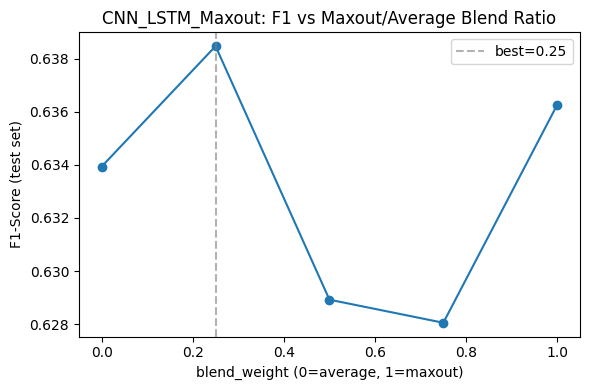

In [21]:
#Plot F1 vs blend_weight, marking the best ratio found
plt.figure(figsize=(6, 4))
plt.plot(blend_df['blend_weight'], blend_df['F1-Score'], marker='o')
plt.axvline(best_blend_weight, color='gray', linestyle='--', alpha=0.6, label=f'best={best_blend_weight}')
plt.xlabel('blend_weight (0=average, 1=maxout)')
plt.ylabel('F1-Score (test set)')
plt.title('CNN_LSTM_Maxout: F1 vs Maxout/Average Blend Ratio')
plt.legend()
plt.tight_layout()
plt.savefig('outputs/uci_blend_ablation.png', dpi=120)
plt.show()

Run Experiments: Deep Learning Models

Training MLP...


Epoch 5/20, train_loss: 0.5554, train_acc: 0.7082, val_loss: 0.5340, val_acc: 0.7250


Epoch 10/20, train_loss: 0.5021, train_acc: 0.7876, val_loss: 0.4365, val_acc: 0.8569


Epoch 15/20, train_loss: 0.4479, train_acc: 0.8223, val_loss: 0.4260, val_acc: 0.8389


Epoch 20/20, train_loss: 0.4137, train_acc: 0.8488, val_loss: 0.3587, val_acc: 0.8729


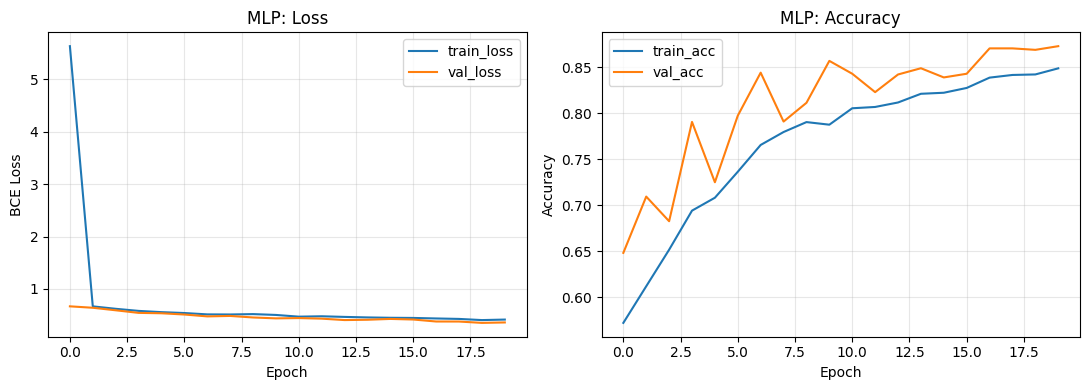

Training CNN...


Epoch 5/20, train_loss: 0.3523, train_acc: 0.8636, val_loss: 0.3222, val_acc: 0.8761


Epoch 10/20, train_loss: 0.2883, train_acc: 0.8933, val_loss: 0.2813, val_acc: 0.8961


Epoch 15/20, train_loss: 0.2705, train_acc: 0.8966, val_loss: 0.2664, val_acc: 0.8985


Epoch 20/20, train_loss: 0.2620, train_acc: 0.8983, val_loss: 0.2618, val_acc: 0.9017


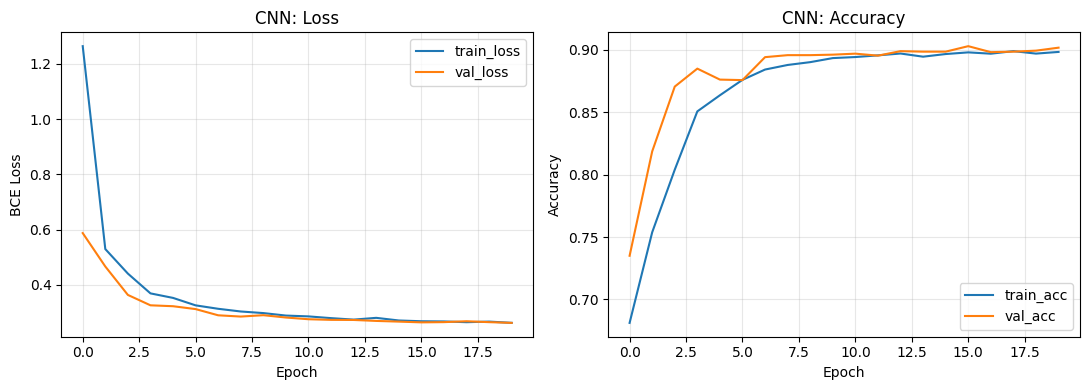

Training LSTM...


Epoch 5/20, train_loss: 0.3062, train_acc: 0.8883, val_loss: 0.3083, val_acc: 0.8865


Epoch 10/20, train_loss: 0.2864, train_acc: 0.8923, val_loss: 0.2800, val_acc: 0.8953


Epoch 15/20, train_loss: 0.2759, train_acc: 0.8940, val_loss: 0.2809, val_acc: 0.8949


Epoch 20/20, train_loss: 0.2703, train_acc: 0.8964, val_loss: 0.2695, val_acc: 0.9001


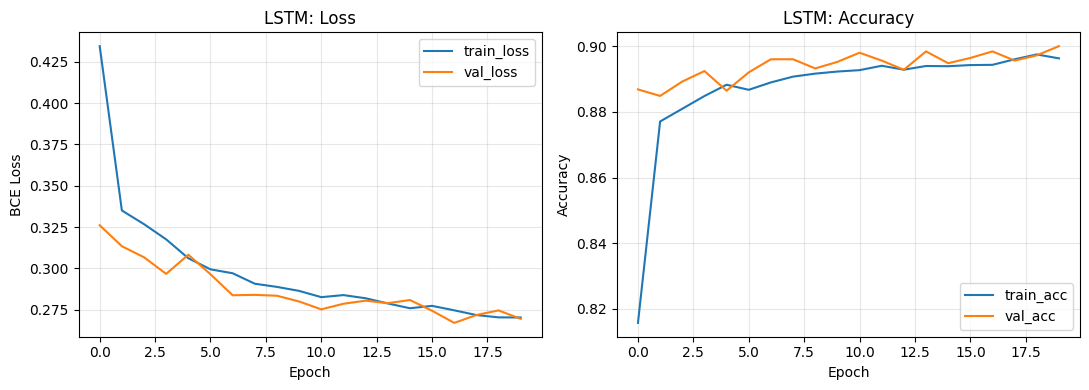

Training CNN_LSTM_Maxout...


Epoch 5/20, train_loss: 0.3346, train_acc: 0.8860, val_loss: 0.3219, val_acc: 0.8937


Epoch 10/20, train_loss: 0.2931, train_acc: 0.8930, val_loss: 0.2937, val_acc: 0.8997


Epoch 15/20, train_loss: 0.2750, train_acc: 0.8952, val_loss: 0.2734, val_acc: 0.8961


Epoch 20/20, train_loss: 0.2621, train_acc: 0.9003, val_loss: 0.2631, val_acc: 0.8997


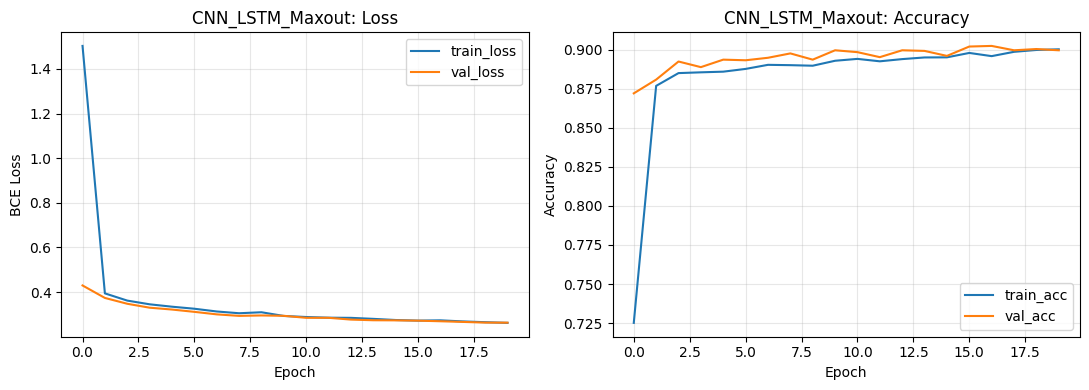

In [22]:
dl_models = {
    'MLP': MLP(in_features=len(feature_cols)),
    'CNN': CNN1D(num_features=len(feature_cols)),
    'LSTM': LSTMNet(),
    'CNN_LSTM_Maxout': CNN_LSTM_Maxout(num_features=len(feature_cols), blend_weight=best_blend_weight),
}

histories = {}
for name, model in dl_models.items():
    print(f'Training {name}...')
    model, history = train_dl_model(model, train_loader, val_loader, epochs=20)
    histories[name] = history
    metrics, y_true, probs = evaluate_dl_model(model, test_loader)
    results[name] = metrics
    predictions[name] = (y_true, probs)
    _, y_true_val, val_probs = evaluate_dl_model(model, val_loader)
    val_predictions[name] = (y_true_val, val_probs)
    fitted_models[name] = model
    torch.save(model.state_dict(), f'{checkpoint_dir}/{name}.pt')
    plot_training_curves(history, name)

Result Table

In [23]:
results_df = pd.DataFrame(results).T
results_df = results_df[['Accuracy', 'ROC AUC', 'Precision', 'Recall', 'F1-Score']].sort_values('F1-Score', ascending=False)
results_df.round(3)

,Accuracy,ROC AUC,Precision,Recall,F1-Score
RF,0.895,0.921,0.661,0.662,0.661
CNN,0.871,0.907,0.560,0.783,0.653
MLP,0.871,0.890,0.561,0.767,0.648
LSTM,0.865,0.912,0.544,0.798,0.647
GB,0.885,0.912,0.627,0.641,0.634
CNN_LSTM_Maxout,0.852,0.911,0.515,0.812,0.630
DT,0.876,0.849,0.603,0.589,0.596
LR,0.659,0.850,0.297,0.877,0.444
KNN,0.763,0.722,0.340,0.563,0.424


Confusion Matrices, ROC Curves, Correlation Matrix

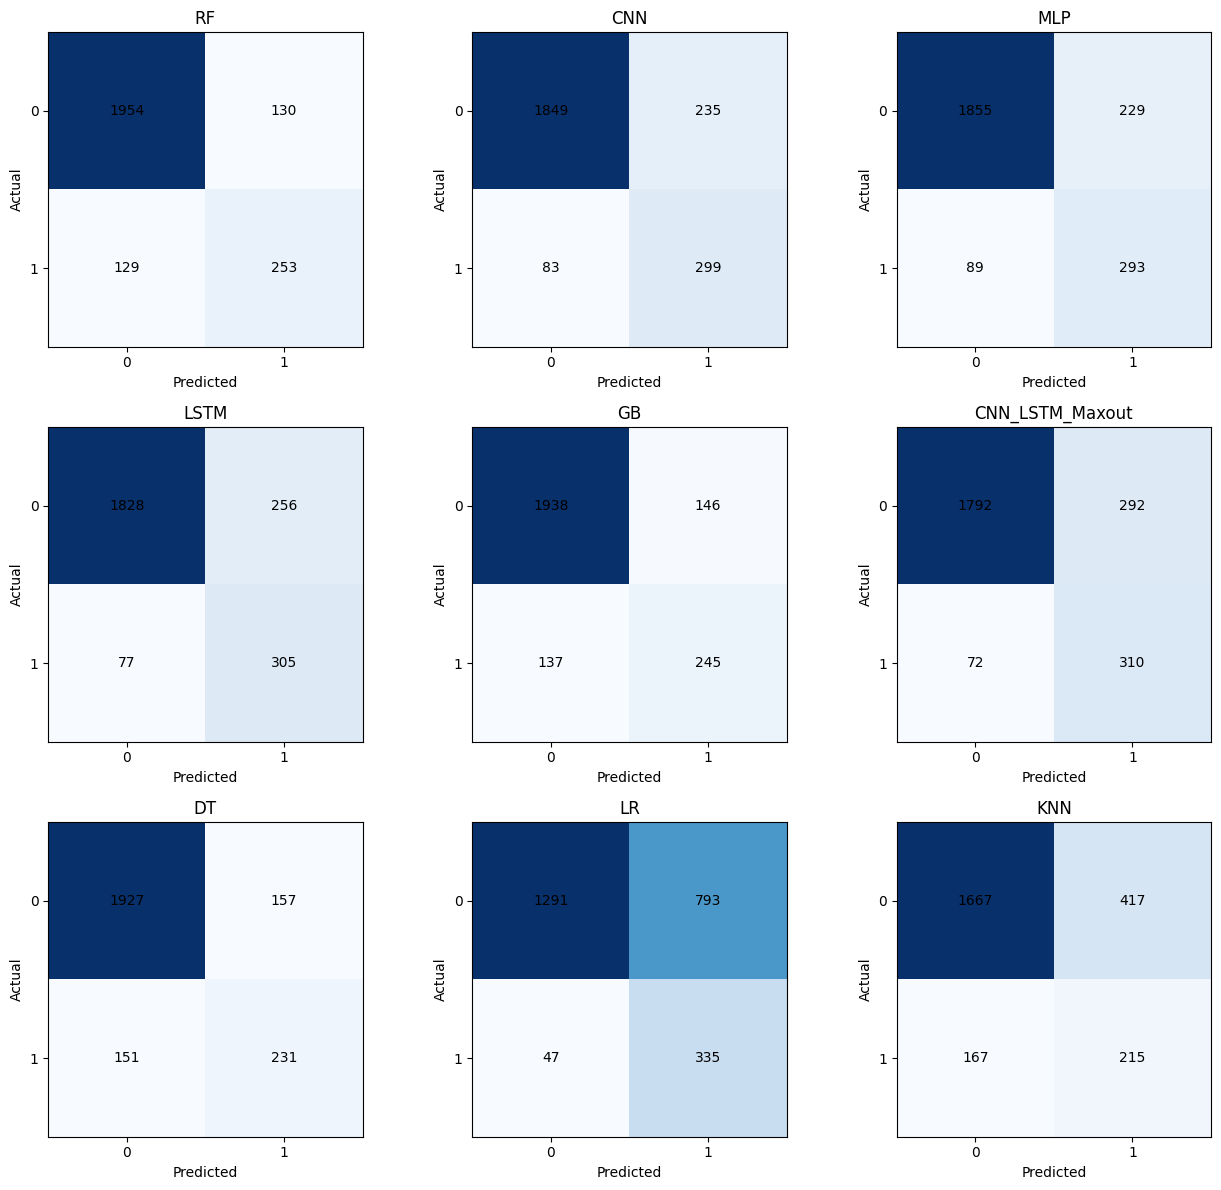

In [24]:
#Confusion matrices for all 9 models, side by side (test set)
model_order = list(results_df.index)
fig, axes = plt.subplots(3, 3, figsize=(13, 12))
for ax, name in zip(axes.flat, model_order):
    y_true, probs = predictions[name]
    y_pred = (probs >= 0.5).astype(int)
    cm = confusion_matrix(y_true, y_pred)
    ax.imshow(cm, cmap='Blues')
    ax.set_title(name)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha='center', va='center', color='black')
plt.tight_layout()
plt.savefig('outputs/uci_confusion_matrices.png', dpi=120)
plt.show()

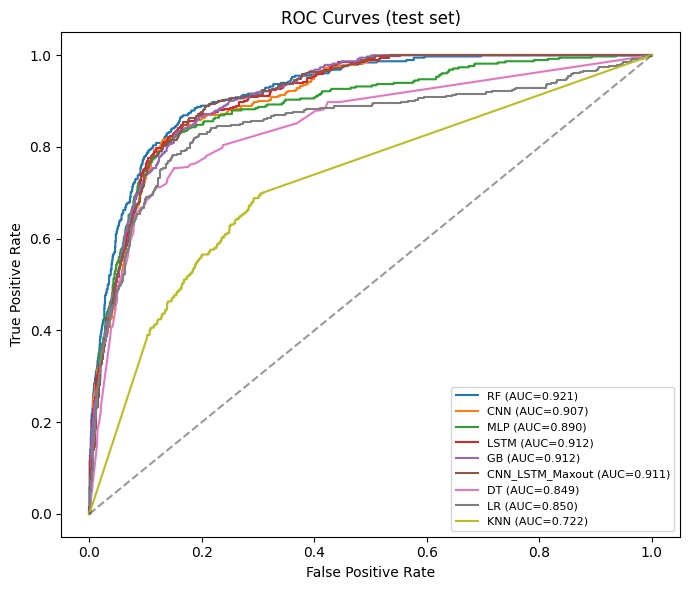

In [25]:
#ROC curves for all 9 models on one plot (test set)
plt.figure(figsize=(7, 6))
for name in model_order:
    y_true, probs = predictions[name]
    fpr, tpr, _ = roc_curve(y_true, probs)
    auc = results_df.loc[name, 'ROC AUC']
    plt.plot(fpr, tpr, label=f'{name} (AUC={auc:.3f})')
plt.plot([0, 1], [0, 1], 'k--', alpha=0.4)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves (test set)')
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig('outputs/uci_roc_curves.png', dpi=120)
plt.show()

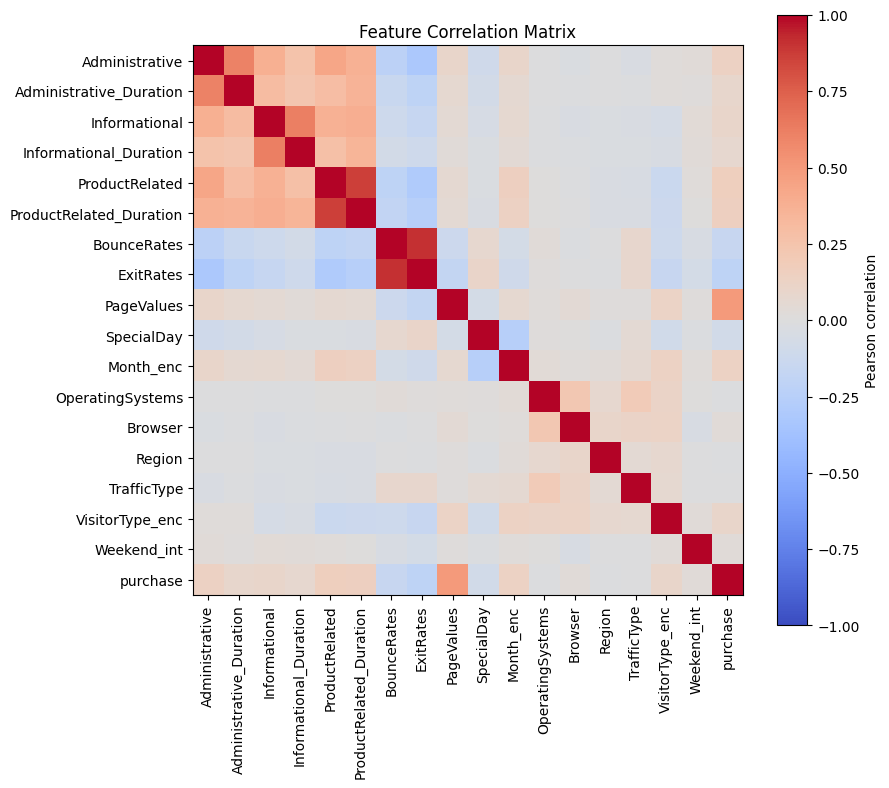

In [26]:
#Pearson correlation matrix of session-level features and the label
corr = df[feature_cols + ['purchase']].corr()
fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=90)
ax.set_yticks(range(len(corr.columns)))
ax.set_yticklabels(corr.columns)
plt.colorbar(im, ax=ax, label='Pearson correlation')
plt.title('Feature Correlation Matrix')
plt.tight_layout()
plt.savefig('outputs/uci_correlation_matrix.png', dpi=120)
plt.show()

Threshold Tuning (per-model optimal decision threshold)

Tương tự notebook REES46: sweep ngưỡng trên tập **validation**, tránh dùng test set, để tìm ngưỡng tối đa hoá F1 cho từng model, rồi áp dụng lên test set.

In [27]:
#Sweep thresholds on the validation split and return the one that maximizes F1
def find_best_threshold(y_val, val_probs, thresholds=np.arange(0.05, 0.96, 0.01)):
    f1s = [f1_score(y_val, (val_probs >= t).astype(int)) for t in thresholds]
    best_idx = int(np.argmax(f1s))
    return thresholds[best_idx], f1s

In [28]:
#Find each model's best threshold on the validation split, then apply it to the held-out test set
thresholds = np.arange(0.05, 0.96, 0.01)
threshold_rows = {}
val_f1_curves = {}
for name in results_df.index:
    y_val_m, val_probs_m = val_predictions[name]
    best_t, f1s = find_best_threshold(y_val_m, val_probs_m, thresholds)
    val_f1_curves[name] = f1s

    y_true, probs = predictions[name]
    y_pred_default = (probs >= 0.5).astype(int)
    y_pred_tuned = (probs >= best_t).astype(int)
    threshold_rows[name] = {
        'best_threshold': best_t,
        'F1 (0.5)': f1_score(y_true, y_pred_default),
        'F1 (tuned)': f1_score(y_true, y_pred_tuned),
        'Precision (tuned)': precision_score(y_true, y_pred_tuned),
        'Recall (tuned)': recall_score(y_true, y_pred_tuned),
        'Accuracy (tuned)': accuracy_score(y_true, y_pred_tuned),
    }

threshold_df = pd.DataFrame(threshold_rows).T
threshold_df = threshold_df[['best_threshold', 'F1 (0.5)', 'F1 (tuned)', 'Precision (tuned)', 'Recall (tuned)', 'Accuracy (tuned)']]
threshold_df = threshold_df.sort_values('F1 (tuned)', ascending=False)
threshold_df.round(3)

,best_threshold,F1 (0.5),F1 (tuned),Precision (tuned),Recall (tuned),Accuracy (tuned)
RF,0.45,0.661,0.666,0.631,0.704,0.891
CNN,0.52,0.653,0.652,0.561,0.777,0.871
LSTM,0.50,0.647,0.647,0.544,0.798,0.865
CNN_LSTM_Maxout,0.64,0.630,0.644,0.548,0.780,0.866
MLP,0.43,0.648,0.628,0.511,0.814,0.850
GB,0.56,0.634,0.612,0.637,0.589,0.884
DT,0.50,0.600,0.596,0.603,0.589,0.876
LR,0.52,0.444,0.555,0.417,0.832,0.794
KNN,0.05,0.424,0.413,0.292,0.702,0.691


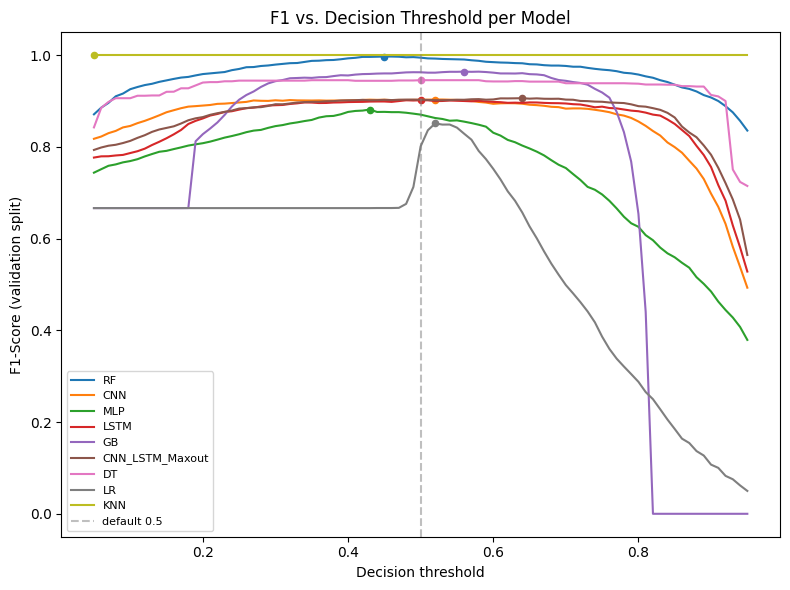

In [29]:
#Plot F1-vs-threshold curves (validation split) for all 9 models, marking each model's chosen threshold
plt.figure(figsize=(8, 6))
for name in results_df.index:
    plt.plot(thresholds, val_f1_curves[name], label=name)
    best_t = threshold_df.loc[name, 'best_threshold']
    best_f1 = max(val_f1_curves[name])
    plt.scatter([best_t], [best_f1], s=20)
plt.axvline(0.5, color='gray', linestyle='--', alpha=0.5, label='default 0.5')
plt.xlabel('Decision threshold')
plt.ylabel('F1-Score (validation split)')
plt.title('F1 vs. Decision Threshold per Model')
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig('outputs/uci_threshold_tuning.png', dpi=120)
plt.show()

Feature Importance: Permutation Importance for the Best Model

In [30]:
best_model_name = results_df.index[0]
best_model = fitted_models[best_model_name]
print('Best model:', best_model_name)

#Permutation importance needs a sklearn-style predict; skip it for the PyTorch models
if best_model_name in param_grids:
    perm = permutation_importance(best_model, X_test, y_test, scoring='f1', n_repeats=10, random_state=seed)
    importance_df = pd.DataFrame({'feature': feature_cols, 'importance': perm.importances_mean})
    importance_df = importance_df.sort_values('importance', ascending=False)
else:
    #Fall back to the best GB model for a sklearn-compatible importance table
    best_model_name = 'GB'
    best_model = fitted_models['GB']
    perm = permutation_importance(best_model, X_test, y_test, scoring='f1', n_repeats=10, random_state=seed)
    importance_df = pd.DataFrame({'feature': feature_cols, 'importance': perm.importances_mean})
    importance_df = importance_df.sort_values('importance', ascending=False)
importance_df

Best model: RF


,feature,importance
8,PageValues,0.468186
10,Month_enc,0.039929
7,ExitRates,0.035370
4,ProductRelated,0.009413
5,ProductRelated_Duration,0.007495
6,BounceRates,0.005189
13,Region,0.004041
12,Browser,0.003482
16,Weekend_int,0.002218
15,VisitorType_enc,0.001591


SHAP Analysis

 17%|===                 | 685/4000 [00:11<00:53]       

 19%|====                | 750/4000 [00:12<00:52]       

 20%|====                | 818/4000 [00:13<00:50]       

 22%|====                | 885/4000 [00:14<00:49]       

 24%|=====               | 952/4000 [00:15<00:48]       

...

 95%|=================== | 3790/4000 [00:58<00:03]       

 96%|=================== | 3854/4000 [00:59<00:02]       

 98%|===================| 3921/4000 [01:00<00:01]       

100%|===================| 3987/4000 [01:01<00:00]       

<Figure size 600x500 with 0 Axes>

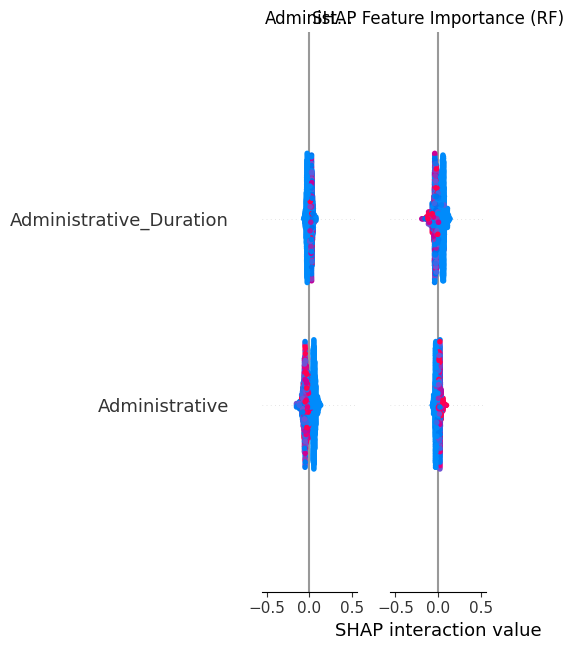

In [31]:
explainer = shap.Explainer(best_model, X_train_bal[:2000])
shap_values = explainer(X_test[:2000], check_additivity=False)

fig = plt.figure(figsize=(6, 5))
shap.summary_plot(shap_values, X_test[:2000], feature_names=np.array(feature_cols), plot_type='bar', show=False)
plt.title(f'SHAP Feature Importance ({best_model_name})')
plt.tight_layout()
plt.savefig('outputs/uci_shap_feature_importance.png', dpi=120)
plt.show()

## Research Questions trên dataset này

Khác với REES46, dataset này **không có giá sản phẩm hay danh mục**, nên không trả lời được RQ1 (category transitions) / RQ2 (price dynamics) như paper gốc. Thay vào đó, bảng permutation importance / SHAP phía trên cho biết:

- **Độ sâu duyệt web** (`ProductRelated`, `ProductRelated_Duration`) và **PageValues** — tín hiệu "giá trị trang trước khi mua" do Google Analytics tính sẵn — thường là nhóm quan trọng nhất, đóng vai trò tương tự `pages_viewed`/`products_viewed` ở REES46.
- **BounceRates/ExitRates** phản ánh mức độ "bỏ dở" hành vi duyệt, có thể xem là proxy gián tiếp cho "abandonment" dù không trực tiếp đo category/price.
- **Month, Region, OperatingSystems, Browser** đóng vai trò proxy yếu cho khía cạnh thời gian/thiết bị/vùng miền (gần với tinh thần RQ3 của paper hơn là RQ1/RQ2), nhưng granularity thô hơn nhiều so với geo thật (lat/long) hay device loại pc/tablet trong paper gốc.